# 07 — Whose chips run Claude, how many megawatts, and is it enough?

**Question:** the S-1 says Claude runs on four chip families (AWS Trainium, Google TPUs, NVIDIA GPUs, AMD GPUs) and lists the dollar commitments behind them (06 §3), but never says *how much* of each. Power is the one unit every deal gets announced in. This notebook adds up the announced megawatts by chip and by year, separates rented from leased from owned, and sets the result against the compute 06's revenue forecast would need.

**Short answer**
1. Announced deals add up to roughly **15.6 GW** of contracted capacity. By chip: **Google TPUs ~6 GW, AWS Trainium ~5 GW, NVIDIA GPUs ~2.6 GW from five landlords, AMD ~2 GW** (§1, `07_compute_mw_by_chip.png`).
2. It arrives late. About **3.5 GW** is online at end-2026 (reported), then ~6.5 GW at end-2027, ~11.4 GW at end-2028 and ~14.9 GW at end-2030, on our ramp assumptions. SpaceXAI's two Memphis data centers (Colossus 1 and 2, ~0.74 GW of NVIDIA GPUs) are a fifth of today's fleet. Anthropic reportedly told analysts on Nov 11 that it won't extend them past mid-2027 (§2, `07_compute_mw_by_year.png`).
3. On a $-per-MW-year scale, **SpaceXAI is the premium, at ~$50M**, ~3x the multi-year rate and ~4x Anthropic's blended ~$13M, the spot rate for capacity available now. Multi-year cloud deals (Google, Nscale, Lambda) run **~$16–18M**. Leasing or buying hardware (AMD, Broadcom TPUs) is cheapest on paper at **~$4–11M** before power and buildings. That's the case for Anthropic Direct (§3, `07_price_per_mw.png`).
4. Against 06's median revenue path, contracted capacity runs **~1.3 GW short in 2027**, and the gap widens every year, to **~7 GW by 2030** (21 GW needed vs 14 GW signed). Only 06's bottom decile fits inside what's signed. That gap is the **opening for the next deals**. In 06's P90 world, Anthropic needs ~37 GW by 2030, about 2.6 times what it has signed (§4, `07_capacity_vs_need.png`).
5. Anthropic **owns almost none of it**: ~55 MW of servers on the balance sheet. ~7 GW arrives from 2027 as finance leases or financed purchases (Google/Broadcom TPUs, AMD), which is ownership in all but name. The rest is rented (§5).

| § | Question | Chart |
|---|---|---|
| 1 | How many megawatts of each chip has Anthropic contracted? | `07_compute_mw_by_chip.png` |
| 2 | When does each deal come online? | `07_compute_mw_by_year.png` |
| 3 | Where is Anthropic getting a deal, and where is it paying a premium? | `07_price_per_mw.png` |
| 4 | Is it enough for the revenue 06 forecasts? | `07_capacity_vs_need.png` |
| 5 | How much does Anthropic actually own? | — |

**Inputs:** announced deals (company releases and press, hand-entered below with source, date and reliability), `data/balance_sheet_detail.csv` (owned servers), `data/forecast.csv` (06's revenue percentiles), `data/kpis.csv` (the S-1's dollar commitments per deal), `data/compute_schedule.csv` (from 03).
**Outputs:** `data/compute_capacity.csv`.

**Read this first.** Almost none of these megawatt numbers is in the S-1; they come from releases and reporting. Most are **"up to"** ceilings, they measure facility power rather than chips, and the year-by-year ramps are our assumptions (each one is written next to its deal). Treat the totals as ±25%. Reliability flags: `primary` = Anthropic or partner release; `press` = a major outlet citing sources; `estimate` = our arithmetic, explained in the row.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from common import *

ppe = load('balance_sheet_detail').query("schedule == 'ppe' and period == '2026-09-30'").set_index('line_item').value
fc = load('forecast').query("metric == 'revenue'").pivot(index='period', columns='percentile', values='value')
B = 1000
YRS = [2026, 2027, 2028, 2029, 2030]

# Hardware cost per MW, used only to turn owned servers ($) into MW. Jensen Huang: NVIDIA now sells
# "40 plus [billion] per gigawatt" (Bg2 Pod, via FourWeekMBA). A rough, NVIDIA-priced conversion.
HW_USD_M_PER_MW = 40.0
owned_mw = ppe['Servers, networking, and infrastructure equipment'] / HW_USD_M_PER_MW
REPORTED_END_2026_MW = 3500   # "more than 3.5 gigawatts ... by the end of 2026" (Anthropic, via Crypto Briefing, 2026-11-03)

# One row per announced deal. mw = contracted ceiling. ramp = MW online at the end of 2026..2030 (OUR assumption unless
# the source gives a date). arrangement: Cloud rental = someone else's chips in their building; Cancellable = same, 90 days'
# notice; Leased or bought = Anthropic Direct (finance leases, or purchase with financing); Owned = on the balance sheet.
DEALS = [
  dict(chip='Google TPU', deal='Google Cloud TPUs (2025 deal)', arrangement='Cloud rental', mw=1000,
       ramp=[1000, 1000, 1000, 1000, 1000], as_of='2025-10-23', reliability='primary',
       source_url='https://www.cnbc.com/2025/10/23/anthropic-google-cloud-deal-tpu.html',
       note='up to 1M TPUs, "well over a gigawatt" online in 2026; S-1 Google CSP contract runs to Jul 2033'),
  dict(chip='Google TPU', deal='Google + Broadcom TPUs (2027+)', arrangement='Leased or bought', mw=5000,
       ramp=[0, 1500, 3500, 5000, 5000], as_of='2026-05-06', reliability='primary',
       source_url='https://www.anthropic.com/news/higher-limits-spacex',
       note='"a 5 GW agreement with Google", online from 2027; S-1: Broadcom finance leases from 2027, extra TPUs 2028-31. Ramp ours'),
  dict(chip='AWS Trainium', deal='Amazon Trainium (incl. Project Rainier)', arrangement='Cloud rental', mw=5000,
       ramp=[1000, 2000, 3000, 4000, 5000], as_of='2026-04-20', reliability='primary',
       source_url='https://www.anthropic.com/news/anthropic-amazon-compute',
       note='up to 5 GW; "nearly 1 GW" of Trainium2/3 by end-2026. Linear ramp to the ceiling is ours'),
  dict(chip='NVIDIA GPU', deal='Microsoft Azure', arrangement='Cloud rental', mw=1000,
       ramp=[0, 500, 1000, 1000, 1000], as_of='2025-11-18', reliability='primary',
       source_url='https://blogs.microsoft.com/blog/2025/11/18/microsoft-nvidia-and-anthropic-announce-strategic-partnerships/',
       note='"up to one gigawatt" of Grace Blackwell / Vera Rubin, no timeline; S-1 payments start Nov 2026. Ramp ours'),
  dict(chip='NVIDIA GPU', deal='SpaceXAI Colossus 1 (Memphis)', arrangement='Cancellable rental', mw=300,
       ramp=[300, 0, 0, 0, 0], as_of='2026-11-11', reliability='primary',
       source_url='https://www.anthropic.com/news/higher-limits-spacex',
       note='"more than 300 megawatts", 220,000+ NVIDIA GPUs. Contract runs into 2029, cancellable after early 2027; '
            'Anthropic reportedly told analysts it will not extend past mid-2027 (teslanorth.com, 2026-11-11), so 0 from end-2027'),
  dict(chip='NVIDIA GPU', deal='SpaceXAI Colossus 2 (Memphis, est.)', arrangement='Cancellable rental', mw=440,
       ramp=[440, 0, 0, 0, 0], as_of='2026-11-11', reliability='estimate',
       source_url='https://www.axios.com/2026/05/20/anthropic-spacex-compute',
       note='our estimate: S-1 ~$3.1B/month at full capacity (Dec 2026) vs $1.25B/month (Axios) for Colossus 1\'s 300 MW -> ~740 MW in all'),
  dict(chip='NVIDIA GPU', deal='Nscale (West Virginia)', arrangement='Cloud rental', mw=460,
       ramp=[0, 460, 460, 460, 460], as_of='2026-08-26', reliability='press',
       source_url='https://www.cnbc.com/2026/08/26/anthropic-and-nscale-strike-45-billion-cloud-deal-sources-say.html',
       note='~460 MW, online end-2027, six years; S-1: up to $44.6B'),
  dict(chip='NVIDIA GPU', deal='Lambda (Texas)', arrangement='Cloud rental', mw=350,
       ramp=[0, 0, 350, 350, 350], as_of='2026-11-10', reliability='press',
       source_url='https://www.tokenpost.com/news/business/53930',
       note='~350 MW at Hut 8 Beacon Point (ComputeStacker); Lambda missed its site-lease deadline, Anthropic will not terminate. 2028 start is ours'),
  dict(chip='AMD GPU', deal='AMD Helios MI450', arrangement='Leased or bought', mw=2000,
       ramp=[0, 1000, 2000, 2000, 2000], as_of='2026-07-22', reliability='primary',
       source_url='https://newsroom.amd.com/news/amd-anthropic-strategic-partnership/',
       note='up to 2 GW, first GW in H1 2027; S-1: "purchase, lease, or access" Helios racks'),
  dict(chip='Owned', deal='Owned servers (balance sheet)', arrangement='Owned', mw=owned_mw,
       ramp=[owned_mw] * 5, as_of='2026-09-30', reliability='estimate', source_url='S-1 Note: property and equipment',
       note=f'S-1: ${ppe["Servers, networking, and infrastructure equipment"]/B:.1f}B gross servers & networking / ${HW_USD_M_PER_MW:.0f}M per MW'),
]
placed_2026 = sum(d['ramp'][0] for d in DEALS)
DEALS.append(dict(chip='Unattributed', deal='Unattributed (reported total minus deals)', arrangement='Cloud rental',
                  mw=REPORTED_END_2026_MW - placed_2026, ramp=[REPORTED_END_2026_MW - placed_2026, 0, 0, 0, 0],
                  as_of='2026-11-03', reliability='estimate', source_url='https://cryptobriefing.com/anthropic-3-5-gw-compute-capacity-2026/',
                  note='>3.5 GW reported for end-2026 minus the deals above (likely Azure, early Broadcom TPUs, older capacity). Dropped after 2026: conservative'))

cap = pd.DataFrame(DEALS)
cap[[f'mw_end_{y}' for y in YRS]] = pd.DataFrame(cap.pop('ramp').tolist())
cap.to_csv(DATA / 'compute_capacity.csv', index=False)
cap[['chip', 'deal', 'arrangement', 'mw'] + [f'mw_end_{y}' for y in YRS]].round(0)

,chip,deal,arrangement,mw,mw_end_2026,mw_end_2027,mw_end_2028,mw_end_2029,mw_end_2030
0,Google TPU,Google Cloud TPUs (2025 deal),Cloud rental,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
1,Google TPU,Google + Broadcom TPUs (2027+),Leased or bought,5000.0,0.0,1500.0,3500.0,5000.0,5000.0
2,AWS Trainium,Amazon Trainium (incl. Project Rainier),Cloud rental,5000.0,1000.0,2000.0,3000.0,4000.0,5000.0
3,NVIDIA GPU,Microsoft Azure,Cloud rental,1000.0,0.0,500.0,1000.0,1000.0,1000.0
4,NVIDIA GPU,SpaceXAI Colossus 1 (Memphis),Cancellable rental,300.0,300.0,0.0,0.0,0.0,0.0
5,NVIDIA GPU,"SpaceXAI Colossus 2 (Memphis, est.)",Cancellable rental,440.0,440.0,0.0,0.0,0.0,0.0
6,NVIDIA GPU,Nscale (West Virginia),Cloud rental,460.0,0.0,460.0,460.0,460.0,460.0
7,NVIDIA GPU,Lambda (Texas),Cloud rental,350.0,0.0,0.0,350.0,350.0,350.0
8,AMD GPU,AMD Helios MI450,Leased or bought,2000.0,0.0,1000.0,2000.0,2000.0,2000.0
9,Owned,Owned servers (balance sheet),Owned,55.0,55.0,55.0,55.0,55.0,55.0


## 1. How many megawatts of each chip has Anthropic contracted?
**Why ask:** "diversified across four chip platforms" can mean an even split or 95% on one vendor. The answer tells you who has leverage over Anthropic's costs, and which software stack its models have to run well on.

**Method:** add up each deal's announced ceiling by chip family. Each segment is one deal, colored by how Anthropic holds the capacity, and estimates are hatched. Megawatts aren't equal across chips (a TPU megawatt and a GPU megawatt don't do the same work), but power is the binding constraint in every deal, and it's the one unit they all disclose.

In [2]:
deals = cap[cap.chip != 'Unattributed']
by_chip = deals.groupby('chip', sort=False).mw.sum()
total = by_chip.sum()
print(f'Contracted: {total/B:,.1f} GW')
(by_chip / B).round(2).to_frame('GW').assign(share=(by_chip / total).round(2))

Contracted: 15.6 GW


,GW,share
chip,,
Google TPU,6.00,0.38
AWS Trainium,5.00,0.32
NVIDIA GPU,2.55,0.16
AMD GPU,2.00,0.13
Owned,0.06,0.00


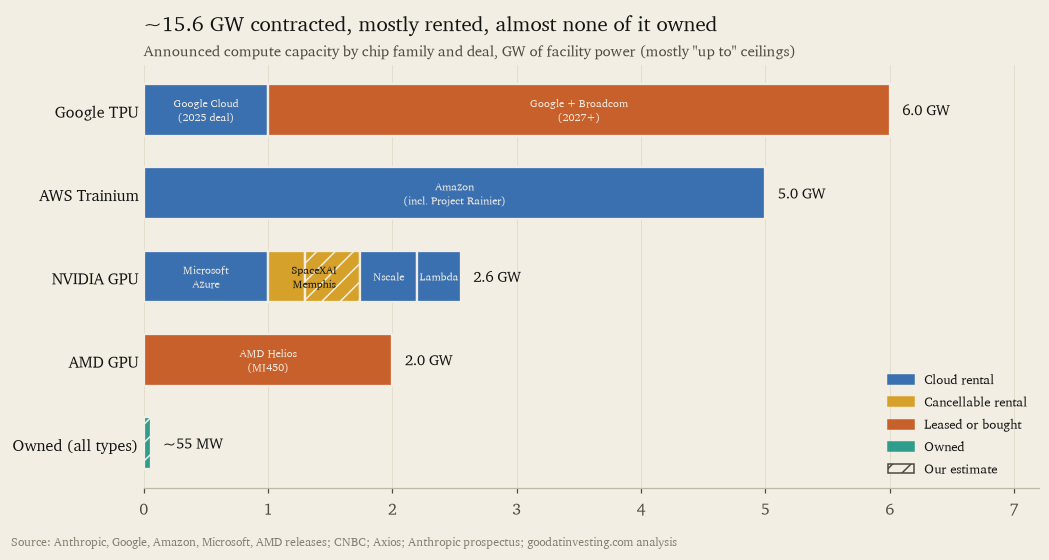

In [3]:
ARR_COLOR = {'Cloud rental': SERIES[0], 'Cancellable rental': SERIES[3], 'Leased or bought': SERIES[1], 'Owned': SERIES[2]}
# Short in-bar labels; the two SpaceXAI sites share one label spanning both segments.
SHORT = {'Google Cloud TPUs (2025 deal)': 'Google Cloud\n(2025 deal)', 'Google + Broadcom TPUs (2027+)': 'Google + Broadcom\n(2027+)',
         'Amazon Trainium (incl. Project Rainier)': 'Amazon\n(incl. Project Rainier)', 'Microsoft Azure': 'Microsoft\nAzure',
         'SpaceXAI Colossus 1 (Memphis)': 'SpaceXAI\nMemphis', 'SpaceXAI Colossus 2 (Memphis, est.)': 'SpaceXAI\nMemphis',
         'Nscale (West Virginia)': 'Nscale', 'Lambda (Texas)': 'Lambda', 'AMD Helios MI450': 'AMD Helios\n(MI450)'}
fig, ax = plt.subplots(figsize=(10.5, 5))
for i, chip in enumerate(by_chip.index):
    left, spans = 0, {}
    for _, d in deals[deals.chip == chip].iterrows():
        w = d.mw / B
        ax.barh(i, w, left=left, color=ARR_COLOR[d.arrangement], height=0.62, edgecolor=SURFACE, linewidth=1.5,
                hatch='//' if d.reliability == 'estimate' else '')
        lab = SHORT.get(d.deal)
        if lab:
            a, b = spans.get(lab, (left, left))
            spans[lab] = (a, left + w)
        left += w
    for lab, (a, b) in spans.items():
        if b - a >= 0.3:
            ax.text((a + b) / 2, i, lab, ha='center', va='center', fontsize=7.5 if b - a >= 0.6 else 7,
                    color=INK if 'SpaceXAI' in lab else SURFACE)
    ax.text(left + 0.1, i, f'{left:,.1f} GW' if left >= 0.1 else f'~{left*B:,.0f} MW', va='center', fontsize=9.5, color=INK)
ax.set_yticks(range(len(by_chip)), [c if c != 'Owned' else 'Owned (all types)' for c in by_chip.index])
ax.invert_yaxis()
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_xlim(0, 7.2)
handles = [Patch(color=c, label=a) for a, c in ARR_COLOR.items()]
handles += [Patch(facecolor=SURFACE, edgecolor=INK2, hatch='//', label='Our estimate')]
ax.legend(handles=handles, loc='lower right', fontsize=8.5)
ax.set_title(f'~{total/B:.1f} GW contracted, mostly rented, almost none of it owned')
subtitle(ax, 'Announced compute capacity by chip family and deal, GW of facility power (mostly "up to" ceilings)')
source(fig, 'Source: Anthropic, Google, Amazon, Microsoft, AMD releases; CNBC; Axios; Anthropic prospectus; goodatinvesting.com analysis')
save(fig, '07_compute_mw_by_chip.png')
plt.show()

**What this shows** (`07_compute_mw_by_chip.png`):
- **Google TPUs are the largest family (~6 GW)**, most of it the 2027+ Google/Broadcom build-out. In dollars (06 §3) it's ~$259B of Google deals plus $161B of Broadcom TPU leases. Google's chip design sits under ~38% of contracted power, and Google is also a shareholder.
- **Trainium is ~5 GW, but that's an "up to."** Only about 1 GW is due by end-2026, and Amazon's dollar floor ($110B over ten years) is well below what 5 GW would cost.
- **NVIDIA comes from five landlords, never NVIDIA itself:** Microsoft, SpaceXAI's two Memphis data centers (Colossus 1, and Colossus 2, which we estimate), Nscale and Lambda. The SpaceXAI block (yellow) is the only big one Anthropic can walk away from on 90 days' notice. It's also the priciest: ~$1.25B a month for Colossus 1's 300 MW is ~$50M per MW-year, several times what the multi-year deals imply.
- **AMD (~2 GW)** is new and starts in 2027: the bet on a fourth supplier.

**On the SpaceXAI "deal in the billions":** there's no new deal. The S-1 discloses up to **$120.5B** through 2029 (about $3.1B a month once everything is delivered in December 2026), which is larger than the ~$45B and ~$84.5B figures reported earlier from SpaceX's own filings. The news on Nov 11 went the other way. Per analyst notes posted by Citrini Research's Jukan, Anthropic said it **won't extend the contract past mid-2027**. Neither company has confirmed this. Musk replied that SpaceX would be "happy to take the compute back." We model that exit in §2.

**Next:** these are totals over the life of the deals. When does each one actually come online?

## 2. When does each deal come online?
**Why ask:** a 5 GW deal that arrives in 2029 doesn't help serve 2027's customers. Payments ramp the same way (03 §1), so timing decides both capacity and cost.

**Method:** for each deal, the MW we expect online at each year-end. Where a source gives a date we use it: Nscale at end-2027, AMD's first GW in H1 2027, Google/Broadcom from 2027. Otherwise we assume a linear ramp to the announced ceiling (the `note` column says which). For SpaceXAI we follow the reported mid-2027 exit, not the contract's 2029 end. "Other" is owned servers (~55 MW) plus the gap between the reported >3.5 GW at end-2026 and the deals we can place. We drop the gap after 2026, which is conservative. The chart shows chip families; the table under it has every deal.

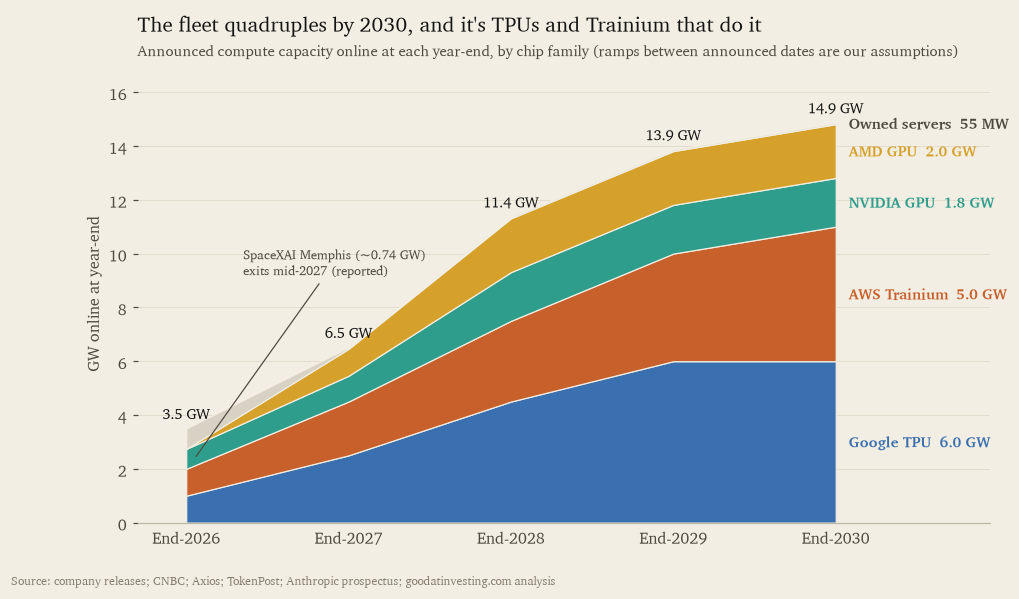

In [4]:
CHIP_COLOR = {'Google TPU': SERIES[0], 'AWS Trainium': SERIES[1], 'NVIDIA GPU': SERIES[2], 'AMD GPU': SERIES[3],
              'Other': PALE}
end_cols = [f'mw_end_{y}' for y in YRS]
cap['family'] = cap.chip.where(cap.chip.isin(CHIP_COLOR), 'Other')           # owned + unattributed -> Other
end_by_chip = cap.groupby('family')[end_cols].sum().reindex(CHIP_COLOR).set_axis(YRS, axis=1)

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.stackplot(YRS, end_by_chip.values / B, colors=list(CHIP_COLOR.values()), edgecolor=SURFACE, linewidth=0.8)
mid = (end_by_chip.cumsum() - end_by_chip / 2)[2030] / B                     # label each band at its 2030 midpoint
for fam, y in mid.items():
    if end_by_chip.loc[fam, 2030] > 0:
        v = end_by_chip.loc[fam, 2030]
        ax.text(2030.08, y, f'{fam}  {v/B:.1f} GW' if fam != 'Other' else f'Owned servers  {v:.0f} MW', va='center', fontsize=9.5, color=CHIP_COLOR[fam]
                if fam != 'Other' else INK2, fontweight='bold')
for yr, t in end_by_chip.sum().items():
    ax.text(yr, t / B + 0.35, f'{t/B:.1f} GW', ha='center', fontsize=9.5, color=INK)
nv26 = end_by_chip.loc[['Google TPU', 'AWS Trainium'], 2026].sum() / B + end_by_chip.loc['NVIDIA GPU', 2026] / B / 2
ax.annotate('SpaceXAI Memphis (~0.74 GW)\nexits mid-2027 (reported)', xy=(2026.05, nv26), xytext=(2026.35, 9.2),
            fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_xticks(YRS, [f'End-{y}' for y in YRS])
ax.tick_params(axis='x', length=0, labelcolor=INK2)
ax.set_xlim(2025.7, 2030.95)
ax.set_ylim(0, 17)
ax.set_ylabel('GW online at year-end')
ax.set_title("The fleet quadruples by 2030, and it's TPUs and Trainium that do it")
subtitle(ax, 'Announced compute capacity online at each year-end, by chip family (ramps between announced dates are our assumptions)')
source(fig, 'Source: company releases; CNBC; Axios; TokenPost; Anthropic prospectus; goodatinvesting.com analysis')
save(fig, '07_compute_mw_by_year.png')
plt.show()

In [5]:
# Every deal, GW online at year-end (the chart above sums these by chip family)
(cap.set_index(['family', 'deal'])[end_cols].set_axis(YRS, axis=1) / B).round(2)

2026  2027  2028  \
family       deal                                                          
Google TPU   Google Cloud TPUs (2025 deal)              1.00  1.00  1.00   
             Google + Broadcom TPUs (2027+)             0.00  1.50  3.50   
AWS Trainium Amazon Trainium (incl. Project Rainier)    1.00  2.00  3.00   
NVIDIA GPU   Microsoft Azure                            0.00  0.50  1.00   
             SpaceXAI Colossus 1 (Memphis)              0.30  0.00  0.00   
             SpaceXAI Colossus 2 (Memphis, est.)        0.44  0.00  0.00   
             Nscale (West Virginia)                     0.00  0.46  0.46   
             Lambda (Texas)                             0.00  0.00  0.35   
AMD GPU      AMD Helios MI450                           0.00  1.00  2.00   
Other        Owned servers (balance sheet)              0.06  0.06  0.06   
             Unattributed (reported total minus deals)  0.70  0.00  0.00   

                                                        2029  2030  
family       deal                                                   
Google TPU   Google Cloud TPUs (2025 deal)              1.00  1.00  
             Google + Broadcom TPUs (2027+)             5.00  5.00  
AWS Trainium Amazon Trainium (incl. Project Rainier)    4.00  5.00  
NVIDIA GPU   Microsoft Azure                            1.00  1.00  
             SpaceXAI Colossus 1 (Memphis)              0.00  0.00  
             SpaceXAI Colossus 2 (Memphis, est.)        0.00  0.00  
             Nscale (West Virginia)                     0.46  0.46  
             Lambda (Texas)                             0.35  0.35  
AMD GPU      AMD Helios MI450                           2.00  2.00  
Other        Owned servers (balance sheet)              0.06  0.06  
             Unattributed (reported total minus deals)  0.00  0.00

**What this shows** (`07_compute_mw_by_year.png`):
- **End-2026 (~3.5 GW)** is a rented fleet: Google Cloud TPUs, Trainium, and SpaceXAI's two Memphis sites (Colossus 1 and 2, about a fifth of the total).
- **End-2027 (~6.5 GW):** the first Google/Broadcom TPUs, the first AMD gigawatt and Nscale arrive, and SpaceXAI leaves. The fleet nearly doubles, on leased TPUs and AMD racks rather than rented GPUs.
- **End-2028 (~11.4 GW)** and **end-2030 (~14.9 GW):** TPUs and Trainium make up three-quarters of the fleet. NVIDIA settles at ~1.8 GW (Azure, Nscale, Lambda).
- If Anthropic *kept* SpaceXAI through 2029, as the contract allows, add ~0.74 GW to 2027 and 2028.

**Next:** these deals cost very different amounts per megawatt. Where is Anthropic getting a deal, and where is it paying a premium?

## 3. Where is Anthropic getting a deal, and where is it paying a premium?
**Why ask:** a megawatt bought on a seven-year contract and a megawatt rented this month aren't the same product, and they aren't the same price. Putting every deal on one scale shows what Anthropic pays for flexibility and speed.

**Method:** **$ per MW-year** = the deal's dollars ÷ the MW-years it delivers over its term. MW-years come from §2's ramp, held flat after 2030. Dollars come from the S-1 (`kpis.csv`), except SpaceXAI, where we use the reported $1.25B a month for Colossus 1's 300 MW.

Three warnings before reading the table:
- **Floors over ceilings.** Amazon's $110B and Microsoft's $44.9B are *minimum* spend, while 5 GW and 1 GW are *maximum* capacity. Dividing a floor by a ceiling gives a **lower bound** on the price, not the price.
- **What the dollars buy differs.** Cloud deals are all-in: chips, building, power, staff. AMD's >$20B buys hardware only, which we spread over a five-year life. Building and power come on top.
- **Benchmarks** are rough: Anthropic's own blended rate (03's committed compute in Q4-2026 ÷ 3.5 GW), Jensen Huang's ~$50B a year to rent a 1 GW AI factory, and his $50–60B to build one.

In [6]:
compute_q4 = load('compute_schedule').set_index('year').loc[2026].sum() * 4   # 03's committed compute, Q4-2026 annualized

def mw_years(ramp, start, end):
    '''MW-years delivered between start and end (decimal years), from year-end ramp values (end-2026..end-2030),
    rising linearly from 0 at the start date and held flat after 2030.'''
    pts = [(start, 0.0)] + [(y + 1.0, v) for y, v in zip(YRS, ramp) if y + 1.0 > start]
    t = np.linspace(start, end, 2000)
    return np.interp(t, *zip(*pts)).mean() * (end - start)

ramp = cap.set_index('deal')[end_cols]
KP = load('kpis').drop_duplicates('metric').set_index('metric')
QUAL = {'>': 'at least', '<': 'up to', '~': 'about'}
PRICE = [  # deal, kpis metric for the $, term start, term end (decimal years), what the $ covers / how to read it
    ('Google Cloud TPUs (2025 deal)', 'commit_google_csp',     2026.25, 2033.5,  'all-in cloud; $ may cover more than this 1 GW'),
    ('Nscale (West Virginia)',        'commit_nscale',         2027.9,  2033.9,  'all-in cloud'),
    ('Lambda (Texas)',                'commit_lambda_aug2026', 2028.0,  2034.0,  'all-in cloud; Aug-2026 agreement only'),
    ('Microsoft Azure',               'commit_microsoft',      2026.83, 2033.5,  'lower bound: $ floor / MW ceiling'),
    ('Amazon Trainium (incl. Project Rainier)', 'commit_amazon', 2026.33, 2036.33, 'lower bound: $ floor / MW ceiling'),
]
rows = []
for deal, metric, t0, t1, basis in PRICE:
    usd, mwy = KP.loc[metric, 'value'], mw_years(ramp.loc[deal], t0, t1)
    rows.append(dict(deal=deal, usd_b=usd / B, qualifier=QUAL.get(KP.loc[metric, 'approx'], ''), years=t1 - t0,
                     avg_gw=mwy / (t1 - t0) / B, usd_m_per_mw_yr=usd / mwy, basis=basis))
rows += [
    dict(deal='SpaceXAI Colossus 1 (Memphis)', usd_b=1.25 * 12, qualifier='per year', years=1, avg_gw=0.3,
         usd_m_per_mw_yr=1250 * 12 / 300, basis='all-in cloud, cancellable; $1.25B/month (Axios)'),
    dict(deal='AMD Helios MI450 (first GW)', usd_b=KP.loc['commit_amd_variable', 'value'] / B, qualifier='at least', years=5,
         avg_gw=1.0, usd_m_per_mw_yr=KP.loc['commit_amd_variable', 'value'] / 1000 / 5,
         basis='hardware only over 5 yrs; + building, power'),
    dict(deal='Benchmark: Anthropic blended today', usd_b=compute_q4 / B, qualifier='per year', years=1,
         avg_gw=REPORTED_END_2026_MW / B, usd_m_per_mw_yr=compute_q4 / REPORTED_END_2026_MW, basis="03's committed compute, Q4-2026 x 4"),
    dict(deal='Benchmark: market rent (Huang)', usd_b=50, qualifier='per year', years=1, avg_gw=1.0, usd_m_per_mw_yr=50.0,
         basis='"$50B a year" to rent a 1 GW AI factory (247 Wall St, Sep 2026)'),
    dict(deal='Benchmark: build cost (Huang)', usd_b=55, qualifier='about', years=5, avg_gw=1.0, usd_m_per_mw_yr=55_000 / 1000 / 5,
         basis='$50-60B per GW, spread over 5 yrs; capital only'),
]
price = pd.DataFrame(rows).set_index('deal').sort_values('usd_m_per_mw_yr', ascending=False)
price['x_blended'] = price.usd_m_per_mw_yr / (compute_q4 / REPORTED_END_2026_MW)
price.round({'usd_b': 1, 'years': 1, 'avg_gw': 2, 'usd_m_per_mw_yr': 1, 'x_blended': 1})

,usd_b,qualifier,years,avg_gw,usd_m_per_mw_yr,basis,x_blended
deal,,,,,,,
SpaceXAI Colossus 1 (Memphis),15.0,per year,1.0,0.30,50.0,"all-in cloud, cancellable; $1.25B/month (Axios)",3.9
Benchmark: market rent (Huang),50.0,per year,1.0,1.00,50.0,"""$50B a year"" to rent a 1 GW AI factory (247 W...",3.9
Lambda (Texas),34.9,about,6.0,0.32,18.1,all-in cloud; Aug-2026 agreement only,1.4
Google Cloud TPUs (2025 deal),121.3,at least,7.2,0.95,17.6,all-in cloud; $ may cover more than this 1 GW,1.4
Nscale (West Virginia),44.6,up to,6.0,0.46,16.3,all-in cloud,1.3
Benchmark: Anthropic blended today,44.9,per year,1.0,3.50,12.8,"03's committed compute, Q4-2026 x 4",1.0
Benchmark: build cost (Huang),55.0,about,5.0,1.00,11.0,"$50-60B per GW, spread over 5 yrs; capital only",0.9
Microsoft Azure,44.9,at least,6.7,0.82,8.2,lower bound: $ floor / MW ceiling,0.6
AMD Helios MI450 (first GW),20.0,at least,5.0,1.00,4.0,"hardware only over 5 yrs; + building, power",0.3


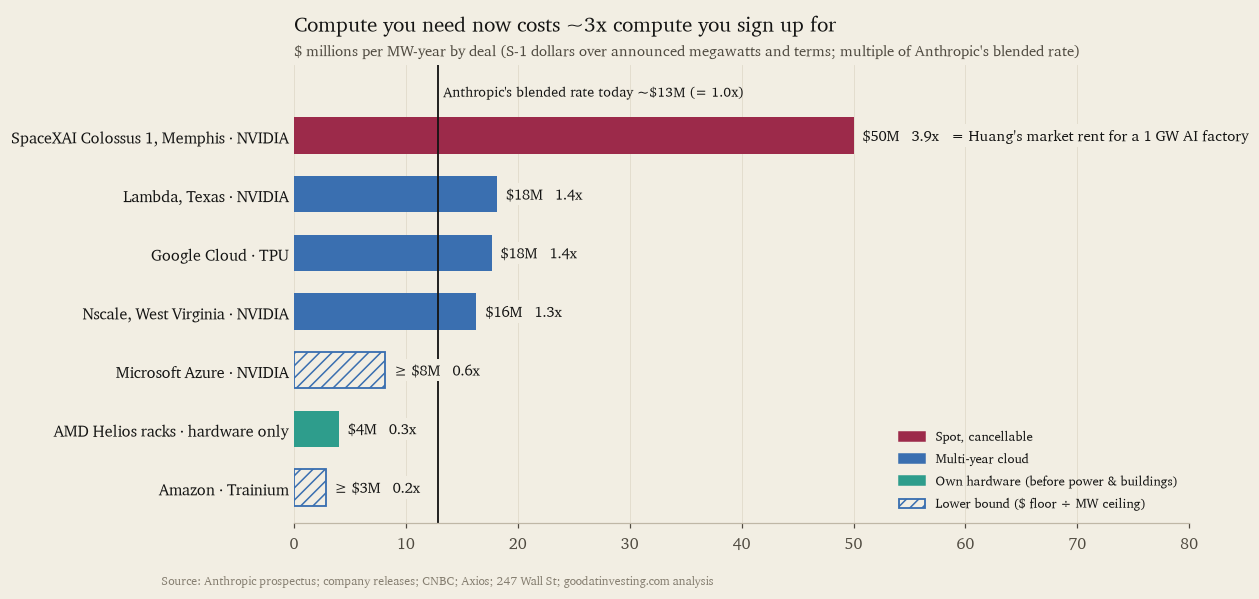

In [7]:
# Deals only; the benchmarks become reference lines. kind = how to read each bar.
NAME = {'SpaceXAI Colossus 1 (Memphis)': 'SpaceXAI Colossus 1, Memphis · NVIDIA',
        'Lambda (Texas)': 'Lambda, Texas · NVIDIA', 'Google Cloud TPUs (2025 deal)': 'Google Cloud · TPU',
        'Nscale (West Virginia)': 'Nscale, West Virginia · NVIDIA', 'Microsoft Azure': 'Microsoft Azure · NVIDIA',
        'AMD Helios MI450 (first GW)': 'AMD Helios racks · hardware only', 'Amazon Trainium (incl. Project Rainier)': 'Amazon · Trainium'}
KIND = {'SpaceXAI Colossus 1 (Memphis)': 'Spot, cancellable', 'Lambda (Texas)': 'Multi-year cloud',
        'Google Cloud TPUs (2025 deal)': 'Multi-year cloud', 'Nscale (West Virginia)': 'Multi-year cloud',
        'Microsoft Azure': 'Lower bound ($ floor ÷ MW ceiling)', 'Amazon Trainium (incl. Project Rainier)': 'Lower bound ($ floor ÷ MW ceiling)',
        'AMD Helios MI450 (first GW)': 'Own hardware (before power & buildings)'}
KIND_STYLE = {'Spot, cancellable': dict(color=NEG), 'Multi-year cloud': dict(color=SERIES[0]),
              'Own hardware (before power & buildings)': dict(color=SERIES[2]),
              'Lower bound ($ floor ÷ MW ceiling)': dict(facecolor=SURFACE, edgecolor=SERIES[0], hatch='///', linewidth=1.2)}
blended = compute_q4 / REPORTED_END_2026_MW
p = price.loc[list(KIND)].sort_values('usd_m_per_mw_yr', ascending=False)

fig, ax = plt.subplots(figsize=(10.5, 5.4))
for i, (deal, r) in enumerate(p.iterrows()):
    ax.barh(i, r.usd_m_per_mw_yr, height=0.62, **KIND_STYLE[KIND[deal]])
    lb = KIND[deal].startswith('Lower')
    txt = f'{"≥ " if lb else ""}${r.usd_m_per_mw_yr:.0f}M   {r.x_blended:.1f}x'
    if deal.startswith('SpaceXAI'):
        txt += "   = Huang's market rent for a 1 GW AI factory"
    ax.text(r.usd_m_per_mw_yr + 0.8, i, txt, va='center', fontsize=9.5, color=INK, zorder=3,
            bbox=dict(facecolor=SURFACE, edgecolor='none', pad=1.5))   # sits on top of the blended line
ax.axvline(blended, color=INK, lw=1.2)
ax.text(blended + 0.5, -0.75, f"Anthropic's blended rate today ~${blended:.0f}M (= 1.0x)", fontsize=9, color=INK, va='center')
ax.set_yticks(range(len(p)), [NAME[d] for d in p.index])
ax.invert_yaxis()
ax.set_ylim(len(p) - 0.4, -1.2)
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_xlim(0, 80)
ax.legend(handles=[Patch(label=k, **v) for k, v in KIND_STYLE.items()], loc='lower right', fontsize=8.5)
ax.set_title('Compute you need now costs ~3x compute you sign up for')
subtitle(ax, '$ millions per MW-year by deal (S-1 dollars over announced megawatts and terms; multiple of Anthropic\'s blended rate)')
source(fig, 'Source: Anthropic prospectus; company releases; CNBC; Axios; 247 Wall St; goodatinvesting.com analysis')
save(fig, '07_price_per_mw.png')
plt.show()

**What this shows** (`07_price_per_mw.png`, and the table above it):
- **The premium: SpaceXAI, at ~$50M per MW-year, ~4x Anthropic's blended rate.** That's the spot price for capacity available *now*, the same as Huang's "market rent" for an AI factory. Anthropic paid it to serve 2026 demand, and that's why a mid-2027 exit is rational once cheaper capacity arrives.
- **The going rate for multi-year cloud: ~$16–18M per MW-year** (Google Cloud, Nscale, Lambda), about 1.3–1.4x the blended rate. That's the price of someone else's chips, building and power on a six-to-seven-year contract.
- **Microsoft (~$8M) and Amazon (~$3M) look cheap, but they're lower bounds.** Dividing the dollar floor by the MW ceiling flatters them. Read the other way, Amazon's $110B floor buys only ~0.7 GW at the going rate. The other ~4 GW is option value Amazon has to fill and Anthropic has to pay for if it uses it.
- **The cheapest megawatt is one you lease or buy:** AMD hardware works out to ~$4M per MW-year, and Huang's build cost to ~$11M, before power and buildings. That gap with the ~$17M cloud rate is the economic case for "Anthropic Direct" (the Broadcom TPU leases and AMD racks). The catch is that Anthropic then carries the obsolescence and utilization risk itself (§5).

**Next:** at these capacities, is there enough compute for the revenue 06 forecasts?

## 4. Is it enough for the revenue 06 forecasts?
**Why ask:** the contracts are Anthropic's bet on its own growth (06 §4). If revenue grows faster than the contracted megawatts, someone will be paid to fill the shortfall. That's an opening for whichever provider has power available. If revenue grows slower, Anthropic pays for idle capacity.

**Method:** turn 06's revenue forecast into megawatts at today's **revenue per MW-year**:

$$\text{MW needed}_y = \frac{\text{revenue}_y}{\text{revenue per MW-year}}, \qquad \text{revenue per MW-year} = \frac{\text{Q4-2026 revenue} \times 4}{\text{MW online at end-2026}}$$

- Q4-2026 revenue is 06's median. MW online is the reported ~3.5 GW. Training capacity is included, so this assumes the training share of the fleet stays about the same.
- **Holding revenue per MW constant** matches 06, which holds revenue per compute dollar constant. Newer chips do more work per watt, but they cost more per watt and token prices keep falling, so the two roughly cancel. The dashed line shows the friendlier case: revenue per MW rising 15% a year.
- **Capacity in a year** is the average of the start and end of the year, so it matches annual revenue.

In [8]:
rev_per_mw = fc.loc['Q4-2026', 'P50'] * 4 / REPORTED_END_2026_MW               # $M of revenue per MW-year
print(f'Revenue per MW-year: ${rev_per_mw:,.1f}M, against committed compute of ${compute_q4/REPORTED_END_2026_MW:,.1f}M per MW-year (§3)')

YEARS_F = [2027, 2028, 2029, 2030]
supply = pd.Series({y: (end_by_chip[y - 1].sum() + end_by_chip[y].sum()) / 2 for y in YEARS_F})   # average MW in the year
need = pd.DataFrame({p: [fc.loc[str(y), p] / rev_per_mw for y in YEARS_F] for p in ['P10', 'P50', 'P90']}, index=YEARS_F)
need['P50 if rev/MW +15%/yr'] = need.P50 / 1.15 ** (np.array(YEARS_F) - 2026)
gap = (need.P50 - supply).rename('P50 shortfall (+) / spare (-)')
pd.concat([supply.rename('contracted (avg in year)'), need, gap], axis=1).div(B).round(1)

Revenue per MW-year: $24.5M, against committed compute of $12.8M per MW-year (§3)


,contracted (avg in year),P10,P50,P90,P50 if rev/MW +15%/yr,P50 shortfall (+) / spare (-)
2027,5.0,5.0,6.3,8.1,5.5,1.3
2028,8.9,7.9,11.6,17.1,8.8,2.6
2029,12.6,10.4,16.8,27.3,11.0,4.2
2030,14.4,12.4,21.3,37.0,12.2,7.0


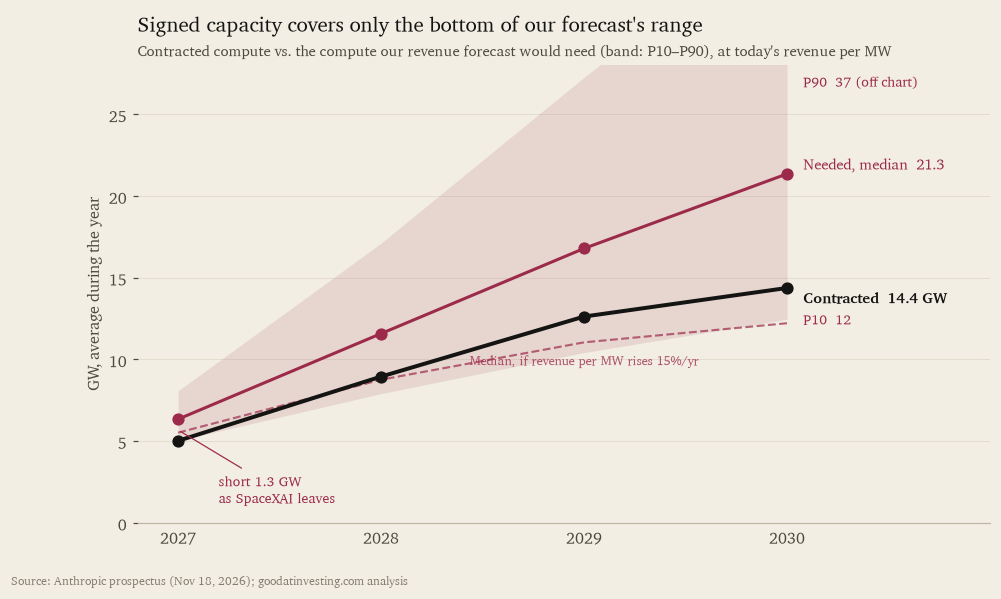

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.fill_between(YEARS_F, need.P10 / B, need.P90 / B, color=NEG, alpha=0.12, lw=0)
ax.plot(YEARS_F, need.P50 / B, color=NEG, marker='o')
ax.plot(YEARS_F, need['P50 if rev/MW +15%/yr'] / B, color=NEG, ls='--', lw=1.4, alpha=0.7)
ax.plot(YEARS_F, supply / B, color=INK, marker='o', lw=2.6)
end = YEARS_F[-1] + 0.08
ax.text(end, supply.iloc[-1] / B - 0.6, f'Contracted  {supply.iloc[-1]/B:.1f} GW', color=INK, fontsize=9.5, fontweight='bold', va='center')
ax.text(end, need.P50.iloc[-1] / B + 0.6, f'Needed, median  {need.P50.iloc[-1]/B:.1f}', color=NEG, fontsize=9.5, va='center')
ax.text(end, 27, f'P90  {need.P90.iloc[-1]/B:.0f} (off chart)', color=NEG, fontsize=9, va='center')
ax.text(end, need.P10.iloc[-1] / B, f'P10  {need.P10.iloc[-1]/B:.0f}', color=NEG, fontsize=9, va='center')
ax.text(2029, need['P50 if rev/MW +15%/yr'][2029] / B - 1.1, 'Median, if revenue per MW rises 15%/yr', color=NEG,
        alpha=0.8, fontsize=8.5, ha='center', va='center')
ax.annotate(f'short {gap[2027]/B:.1f} GW\nas SpaceXAI leaves', xy=(2027, (supply[2027] + need.P50[2027]) / 2 / B),
            xytext=(2027.2, 1.2), fontsize=9, color=NEG, arrowprops=dict(arrowstyle='-', color=NEG, lw=0.8))
ax.set_xticks(YEARS_F, [str(y) for y in YEARS_F])
ax.tick_params(axis='x', length=0, labelcolor=INK2)
ax.set_xlim(2026.8, 2031.0)
ax.set_ylim(0, 28)
ax.set_ylabel('GW, average during the year')
ax.set_title("Signed capacity covers only the bottom of our forecast's range")
subtitle(ax, "Contracted compute vs. the compute our revenue forecast would need (band: P10–P90), at today's revenue per MW")
source(fig)
save(fig, '07_capacity_vs_need.png')
plt.show()

**What this shows** (`07_capacity_vs_need.png`):
- **Revenue per MW-year is ~$25M today**, against ~$13M of committed compute per MW-year (§3): a ~48% gross margin on compute, if all of it went to serving.
- **The shortfall starts in 2027:** median revenue needs ~6.3 GW on average, and contracts provide ~5.0 GW. The ~1.3 GW gap opens just as SpaceXAI leaves. Exiting the priciest capacity (§3) makes sense only if Anthropic expects the Google/Broadcom TPUs and AMD racks to arrive on time, or can fill the gap more cheaply elsewhere.
- **2028–2030:** the median pulls away from what's signed: ~3 GW short in 2028, ~4 GW in 2029, ~7 GW in 2030. Even 06's P10 world needs most of what's contracted by 2030 (~12 of ~14 GW). The top decile needs ~37 GW, about 2.6 times what's contracted. With 06's 30–55% share of AI, the signed fleet looks sized for a smaller company than the one we simulate (06 §4).
- **The opening.** That upside gap is the market for the *next* deals. On §3's prices it goes to whoever has powered capacity ready: NVIDIA neoclouds at ~$17M per MW-year if Anthropic can wait a year, and spot capacity like SpaceXAI's at ~$50M if it can't. TPUs and Trainium are cheaper but come with multi-year lead times.
- If chips raise revenue per MW 15% a year (dashed), the median still runs short in 2027 (~0.5 GW), is about matched in 2028, and is covered from 2029.

**Next:** of all this capacity, how much is Anthropic's own?

## 5. How much does Anthropic actually own?
**Why ask:** owning chips means paying up front and carrying the obsolescence risk. Renting means paying the landlord's margin but being able to walk away when a contract ends. The mix tells you which risk Anthropic's shareholders carry.

**Method:** owned capacity comes from the balance sheet. "Servers, networking, and infrastructure equipment" in the S-1's property-and-equipment note (which also holds finance-lease assets that have started) is turned into MW at ~$40M of hardware per MW. For everything else, we follow the S-1's own description of each deal.

In [10]:
own = deals.groupby('arrangement').mw.sum().reindex(ARR_COLOR)
print(f'Owned servers: ${ppe["Servers, networking, and infrastructure equipment"]/B:.1f}B gross -> ~{owned_mw:,.0f} MW '
      f'= {owned_mw/total:.1%} of contracted power. Construction in progress: ${ppe["Construction in progress"]/B:.1f}B')
(own / B).round(2).to_frame('GW').assign(share=(own / total).round(3))

Owned servers: $2.2B gross -> ~55 MW = 0.4% of contracted power. Construction in progress: $0.9B


,GW,share
arrangement,,
Cloud rental,7.81,0.500
Cancellable rental,0.74,0.047
Leased or bought,7.00,0.449
Owned,0.06,0.004


**What this shows:**
- **Owned: ~55 MW, well under 1%.** Servers and networking gear are $2.2B gross (plus $0.9B under construction), against ~$40B a year of compute *expense* (06 §3). Anthropic isn't a hardware owner today.
- **Leased or bought: ~7 GW, all from 2027.** The Broadcom TPU racks are **finance leases**: Anthropic gets the equipment for five years and owes fixed rent, and the accounts carry it as an asset with matching debt. That's ownership with a payment plan, and it's non-cancelable. The extra Google TPUs may be bought with five-year financing, and AMD's Helios racks may be bought or leased (S-1). As these arrive, the balance sheet goes from almost no hardware to tens of billions of dollars of it.
- **Rented: ~8.5 GW**, including the ~0.74 GW at SpaceXAI that can be cancelled (and reportedly will be).

That's the "Anthropic Direct" strategy the S-1 describes (06 §3): rent today, then shift toward chips Anthropic controls in leased data centers from 2027. It should be cheaper per unit of compute. The cost is the risk of being stuck with yesterday's chips, which today sits with Google, Amazon and Microsoft and moves onto Anthropic for the 2027+ fleet.

## Findings, by section
1. Announced deals add up to ~15.6 GW contracted: TPU ~6, Trainium ~5, NVIDIA ~2.6 (five landlords, including SpaceXAI's two Memphis sites), AMD ~2. The SpaceXAI contract is up to $120.5B through 2029, not a new deal, and Anthropic reportedly won't extend it past mid-2027.
2. The fleet is ~3.5 GW at end-2026, then ~6.5 / ~11.4 / ~14.9 GW at end-2027 / 2028 / 2030. Leased TPUs and AMD racks replace rented SpaceXAI GPUs in 2027.
3. $ per MW-year: SpaceXAI ~$50M (spot premium, matches Huang's market rent), multi-year cloud ~$16–18M, Microsoft and Amazon lower bounds ~$3–8M (floor ÷ ceiling), owned or leased hardware ~$4–11M before power and buildings. Anthropic's blended rate today is ~$13M.
4. Against 06's median, capacity is ~1.3 GW short in 2027 and ~7 GW short by 2030. The P90 world needs ~37 GW by 2030, about 2.6 times what's signed. That gap is the opening for the next round of deals.
5. Owned hardware is ~55 MW (~$2.2B). ~7 GW arrives from 2027 as finance leases or financed purchases, and ~8.5 GW is rented.

**Caveats**
- Nearly every megawatt figure comes from releases or press, not the S-1. "Up to" figures are ceilings. Some deals may overlap: Amazon's 5 GW may include Project Rainier, and Google's 2025 TPUs may sit inside the 5 GW agreement.
- Year-by-year ramps are our assumptions wherever a source gives no date. Colossus 2 (~440 MW) is our estimate. The SpaceXAI exit is unconfirmed analyst notes, and Lambda's site is in doubt.
- MW are facility power, not compute. Revenue per MW is calibrated on one quarter and a reported (not filed) 3.5 GW, and it moves with chip efficiency and token prices.
- $ per MW-year mixes S-1 dollar floors with press MW ceilings, and terms and ramps that are partly ours. Read it as a scale (spot vs. multi-year vs. own), not as contract prices.
- The owned-MW conversion uses NVIDIA-level pricing ($40M per MW). Cheaper hardware would mean more MW, but still well under 1% of the total.

**Open items:** check the priced S-1 amendment and any 10-Q for capacity disclosures. Confirm or refute the SpaceXAI non-extension, and watch the cancellation window (early 2027). Add the Fluidstack data centers ($50B, Texas and New York) once a megawatt figure is published; they likely house the Broadcom TPUs, so we don't count them separately. Track new deals against the §4 gap, and price them on the §3 scale.